In [1]:
import xarray as xr
import xroms
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [2]:
g = xr.open_dataset('/projects/f_omg_1/moa/moana/moana_grid_N50.nc')
g['zeta'] = xr.zeros_like(g.h)
grid, xgrid = xroms.roms_dataset(g, Vtransform=2)

Text(0, 0.5, 'z (m)')

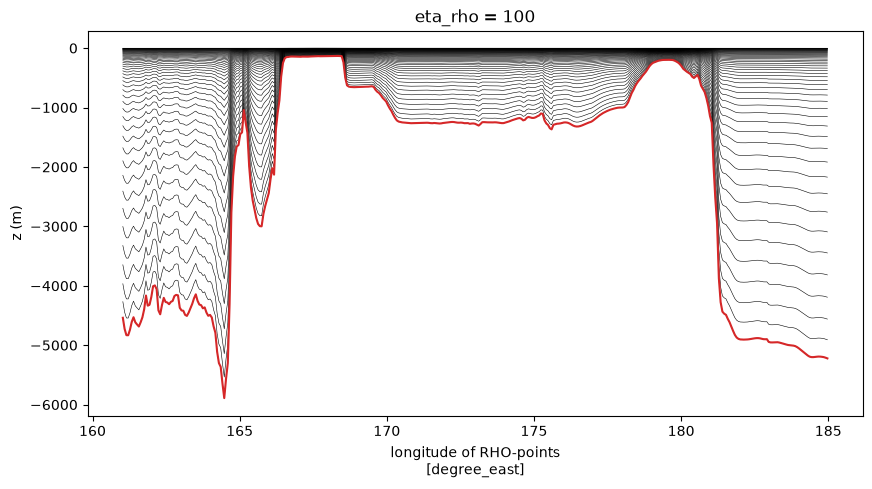

In [3]:
sec = grid.isel(eta_rho=100)
ocean = sec.mask_rho == 1

fig, ax = plt.subplots(figsize=(10, 5))
sec.z_w.where(ocean).plot.line(x="lon_rho", hue="s_w", add_legend=False, color="k", lw=0.4, ax=ax)
(-sec.h).where(ocean).plot(x="lon_rho", color="tab:red", lw=1.5, ax=ax)
ax.set_ylabel("z (m)")

In [4]:
# loading cmems input file
ds1 = xr.open_dataset('/projects/f_omg_1/moa/moana/oceanum_input/initial_cond/ic_uo_vo_raw_2026-01-01.nc')
ds2 = xr.open_dataset('/projects/f_omg_1/moa/moana/oceanum_input/initial_cond/ic_uo_vo_raw_2025-01-01.nc')

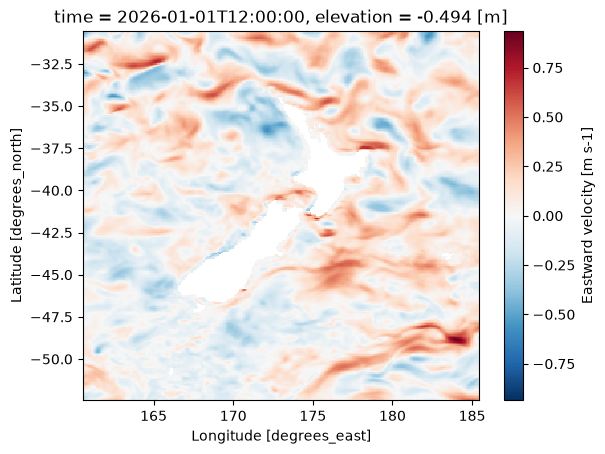

In [5]:
ds1.uo.isel(time=2, elevation=-1).plot()

In [6]:
z_u = grid.z_rho_u.reset_coords(drop=True)
lon_u = (grid.lon_u % 360).reset_coords(drop=True)
lat_u = grid.lat_u.reset_coords(drop=True)
mask_u = grid.mask_u.reset_coords(drop=True)

In [7]:
assert float(abs(grid.angle).max()) < 1e-3, "grid is rotated: u must be rotated using vo as well"
# put a note on the top that this code should be updated in teh case where the grid is rotated

In [8]:
VAR, LON, LAT, DEPTH, TIME = "uo", "longitude", "latitude", "elevation", "time"

In [9]:
cm = ds1[VAR].isel({TIME: 0}).load()
cm = cm.assign_coords({LON: cm[LON] % 360}).sortby(LON)
t0 = cm[TIME].values
print(dict(cm.sizes), "| NaN fraction:", round(float(cm.isnull().mean()), 3))

{'elevation': 50, 'latitude': 263, 'longitude': 299} | NaN fraction: 0.249


In [10]:
assert bool(cm.notnull().any()), "CMEMS field is all NaN"

In [11]:
def flood_fill(da, max_passes=None):
    """Fill NaNs with the mean of valid neighbours at the same depth, one ring of cells per pass."""
    n = 0
    while bool(da.isnull().any()) and (max_passes is None or n < max_passes):
        da = da.fillna(da.rolling({LON: 3, LAT: 3}, center=True, min_periods=1).mean())
        n += 1
    return da
 


In [12]:
# 3a. Same-depth neighbours first (right for slopes and coasts), within N_LATERAL cells
N_LATERAL = 10                                     # ~0.8 deg at 1/12 deg
cm_f = flood_fill(cm, max_passes=N_LATERAL)
 
# 3b. Anything still missing below the CMEMS seafloor: copy each column's deepest valid value downward
cm_f = cm_f.bfill(DEPTH)          # axis is deep -> surface, so "backward" = toward the seafloor
 

In [13]:
cm_f.isnull().values.any()
print(cm_f.isnull().values.sum())

3300


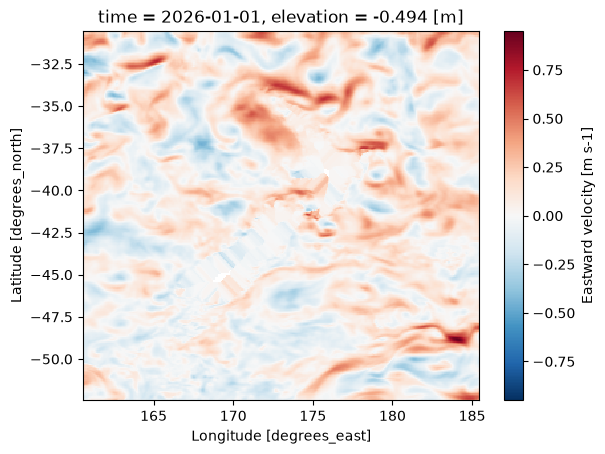

In [14]:
cm_f.isel(elevation=-1).plot()

In [15]:
cm_f = flood_fill(cm_f)

In [16]:

# %% 4. Horizontal: CMEMS -> ROMS u-points (bilinear), on every CMEMS depth level
cm_h = cm_f.interp({LON: lon_u, LAT: lat_u})       # (depth, eta_rho, xi_u)
 

In [17]:
cm_h

<xarray.DataArray 'uo' (elevation: 50, eta_rho: 467, xi_u: 396)> Size: 74MB
array([[[ 0.02241702,  0.02142087,  0.02035102, ...,  0.04307469,
          0.0283846 ,  0.01160926],
        [ 0.02202239,  0.0212676 ,  0.02106299, ...,  0.00839515,
         -0.0032126 , -0.0171618 ],
        [ 0.02174233,  0.02143772,  0.02217445, ..., -0.02785631,
         -0.03638561, -0.04702687],
        ...,
        [-0.01141332, -0.00806283, -0.00402188, ..., -0.01880397,
         -0.02038061, -0.02253954],
        [-0.01306433, -0.01017318, -0.006082  , ..., -0.00572529,
         -0.00961597, -0.01415126],
        [-0.01304074, -0.01056728, -0.00684167, ...,  0.011866  ,
          0.00146667, -0.00706618]],

       [[ 0.02241702,  0.02142087,  0.02035102, ...,  0.04307469,
          0.0283846 ,  0.01160926],
        [ 0.02202239,  0.0212676 ,  0.02106299, ...,  0.00839515,
         -0.0032126 , -0.0171618 ],
        [ 0.02174233,  0.02143772,  0.02217445, ..., -0.02785631,
         -0.03638561, -0.04702687],
...
        [ 0.37428983,  0.38429267,  0.39908276, ...,  0.136191  ,
          0.12796789,  0.12147939],
        [ 0.37279939,  0.37593394,  0.38348699, ...,  0.1326965 ,
          0.12376947,  0.11580213],
        [ 0.3845662 ,  0.37867939,  0.37657084, ...,  0.12398881,
          0.11384688,  0.1043753 ]],

       [[-0.01815021, -0.02107251, -0.02333954, ...,  0.27021526,
          0.24950904,  0.23599628],
        [-0.00310009, -0.00594047, -0.01091563, ...,  0.20382459,
          0.1847596 ,  0.17366303],
        [ 0.01027531,  0.0070157 , -0.00043327, ...,  0.1426395 ,
          0.12556576,  0.11711314],
        ...,
        [ 0.37914633,  0.38869757,  0.40305349, ...,  0.13402975,
          0.12588148,  0.11951435],
        [ 0.37663273,  0.37942392,  0.38672607, ...,  0.13056598,
          0.12173101,  0.11389533],
        [ 0.38798399,  0.38188398,  0.379594  , ...,  0.12185471,
          0.11180163,  0.10245367]]], shape=(50, 467, 396))
Coordinates:
  * elevation  (elevation) float32 200B -5.728e+03 -5.275e+03 ... -1.541 -0.494
  * eta_rho    (eta_rho) int64 4kB 0 1 2 3 4 5 6 ... 460 461 462 463 464 465 466
  * xi_u       (xi_u) int64 3kB 0 1 2 3 4 5 6 7 ... 389 390 391 392 393 394 395
    longitude  (eta_rho, xi_u) float64 1MB 161.1 161.1 161.2 ... 184.9 184.9
    latitude   (eta_rho, xi_u) float64 1MB -51.98 -51.98 ... -31.03 -31.03
    time       datetime64[ns] 8B 2026-01-01
Attributes:
    cell_methods:   area: mean
    long_name:      Eastward velocity
    standard_name:  eastward_sea_water_velocity
    unit_long:      Meters per second
    units:          m s-1
    valid_max:      5
    valid_min:      -5

In [18]:

# %% 5. Vertical: CMEMS depth levels -> ROMS s-levels, column by column
# np.interp holds the end values beyond the data: above CMEMS's top level and below its bottom level
u = xr.apply_ufunc(
    np.interp, z_u, cm_h[DEPTH], cm_h,
    input_core_dims=[["s_rho"], [DEPTH], [DEPTH]],
    output_core_dims=[["s_rho"]],
    vectorize=True,
).transpose("s_rho", "eta_rho", "xi_u")
u.attrs = {"long_name": "u-momentum component", "units": "meter second-1"}   # not z_u's attributes

In [19]:
u = u.where(mask_u ==1, 0)

In [20]:

ocean = mask_u == 1
assert not u.isnull().any(), "NaNs left in u"

In [21]:
# interpolation and neighbour-averaging can't create values outside the CMEMS range
assert float(u.where(ocean).min()) >= float(cm.min()) and float(u.where(ocean).max()) <= float(cm.max())
print(f"CMEMS uo: {float(cm.min()):.3f} to {float(cm.max()):.3f} m/s")
print(f"ROMS u:   {float(u.where(ocean).min()):.3f} to {float(u.where(ocean).max()):.3f} m/s")
 

CMEMS uo: -0.581 to 0.951 m/s
ROMS u:   -0.528 to 0.944 m/s


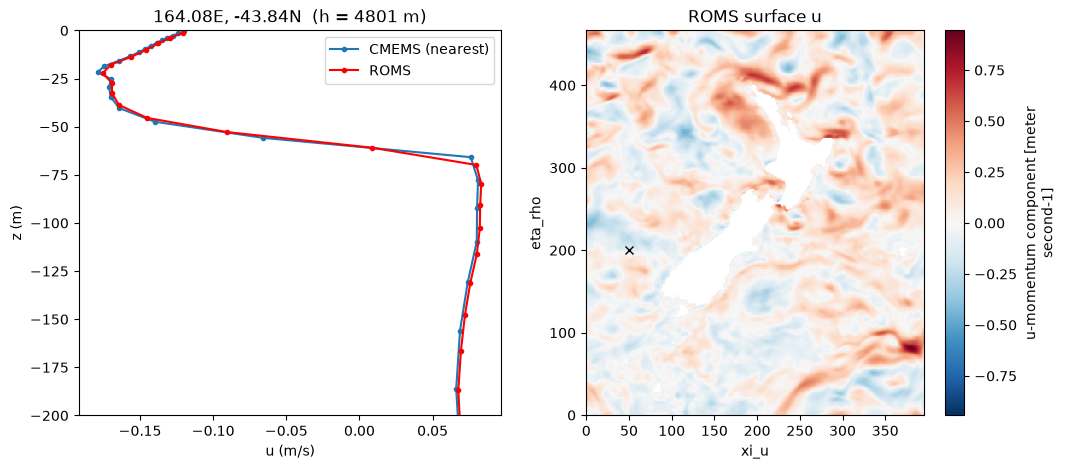

In [22]:
# %% 7. Visual check: one ocean column, CMEMS vs ROMS
import matplotlib.pyplot as plt

j, i = 200, 50                                     # any ocean u-point
ZOOM = -200                                        # elevation (m) to zoom to; None for full column
assert bool(ocean[j, i]), "pick an ocean point"
pt_lon, pt_lat = float(lon_u[j, i]), float(lat_u[j, i])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
cm.sel({LON: pt_lon, LAT: pt_lat}, method="nearest").plot(y=DEPTH, ax=ax1, marker=".", label="CMEMS (nearest)")
ax1.plot(u[:, j, i], z_u[:, j, i], "r.-", label="ROMS")
if ZOOM is not None:
    ax1.set_ylim(ZOOM, 0)
ax1.set_xlabel("u (m/s)"); ax1.set_ylabel("z (m)"); ax1.legend()
ax1.set_title(f"{pt_lon:.2f}E, {pt_lat:.2f}N  (h = {float(grid.h[j, i]):.0f} m)")

u.isel(s_rho=-1).where(ocean).plot(ax=ax2)
ax2.plot(i, j, "kx")
ax2.set_title("ROMS surface u")
plt.show()

In [63]:
cm.elevation.values

<xarray.DataArray 'elevation' (elevation: 50)> Size: 200B
array([-5.727917e+03, -5.274784e+03, -4.833291e+03, -4.405224e+03,
       -3.992484e+03, -3.597032e+03, -3.220820e+03, -2.865703e+03,
       -2.533336e+03, -2.225078e+03, -1.941893e+03, -1.684284e+03,
       -1.452251e+03, -1.245291e+03, -1.062440e+03, -9.023393e+02,
       -7.633331e+02, -6.435668e+02, -5.410889e+02, -4.539377e+02,
       -3.802130e+02, -3.181274e+02, -2.660403e+02, -2.224752e+02,
       -1.861256e+02, -1.558507e+02, -1.306660e+02, -1.097293e+02,
       -9.232607e+01, -7.785385e+01, -6.580727e+01, -5.576429e+01,
       -4.737369e+01, -4.034405e+01, -3.443415e+01, -2.944473e+01,
       -2.521141e+01, -2.159882e+01, -1.849556e+01, -1.581007e+01,
       -1.346714e+01, -1.140500e+01, -9.572997e+00, -7.929560e+00,
       -6.440614e+00, -5.078224e+00, -3.819495e+00, -2.645669e+00,
       -1.541375e+00, -4.940250e-01], dtype=float32)
Coordinates:
  * elevation  (elevation) float32 200B -5.728e+03 -5.275e+03 ... -1.541 -0.494
    time       datetime64[ns] 8B 2026-01-01
Attributes:
    axis:           Z
    long_name:      Elevation
    positive:       up
    standard_name:  elevation
    unit_long:      Meters
    units:          m